# 04 · Sampling

A fitted network is a generative model: `sample(n)` draws `n` joint rows,
parents before children (ancestral sampling).  We compare the samples with the
true distribution, use clamped evidence with importance weights, and draw
samples under interventions.

- **NBN API:** `sample(n, evidence=..., do=..., return_log_prob=..., return_log_weight=...)`,
  `nbn.ancestral_sample`, `log_prob`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth (the hybrid network of notebook 01, without `Runoff`):

    Rain       ~ Bernoulli(0.3)
    Sprinkler  | Rain             table
    WetGrass   | Rain, Sprinkler  table
    Soil       | WetGrass = 0  ~  N(-1, 0.5^2)
    Soil       | WetGrass = 1  ~  0.5 N(1.5, 0.3^2) + 0.5 N(3, 0.3^2)
    Growth     | Soil          ~  N(0.8 Soil + 0.5, (0.15 + 0.25 |Soil - 1|)^2)

In [1]:
import itertools
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import MDNMechanism, NeuralBayesianNetwork, ancestral_sample, seed_all
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, INK = "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


In [2]:
P_RAIN = torch.tensor([0.7, 0.3])
P_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])
P_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]], [[0.15, 0.85], [0.02, 0.98]]])
EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
         ("WetGrass", "Soil"), ("Soil", "Growth")]
VARIABLES = {"Rain": ("discrete", 2), "Sprinkler": ("discrete", 2), "WetGrass": ("discrete", 2),
             "Soil": ("continuous", 1), "Growth": ("continuous", 1)}


def normal_pdf(x, mean, std):
    return torch.exp(-0.5 * ((x - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))


def soil_pdf(x, wet: int):
    if wet:
        return 0.5 * normal_pdf(x, 1.5, 0.3) + 0.5 * normal_pdf(x, 3.0, 0.3)
    return normal_pdf(x, -1.0, 0.5)


def growth_pdf(g, soil):
    return normal_pdf(g, 0.8 * soil + 0.5, 0.15 + 0.25 * (soil - 1.0).abs())


def sample_truth(n: int) -> dict:
    rain = torch.multinomial(P_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(P_SPRINKLER[rain, 1]).long()
    wet = torch.bernoulli(P_WET[rain, sprinkler, 1]).long()
    soil_wet = torch.where(torch.rand(n) < 0.5, 3.0, 1.5) + 0.3 * torch.randn(n)
    soil = torch.where(wet == 1, soil_wet, -1.0 + 0.5 * torch.randn(n))
    growth = 0.8 * soil + 0.5 + (0.15 + 0.25 * (soil - 1.0).abs()) * torch.randn(n)
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet, "Soil": soil[:, None],
            "Growth": growth[:, None]}


# exact discrete joint P(Rain, Sprinkler, WetGrass) and the marginal P(WetGrass)
JOINT = P_RAIN[:, None, None] * P_SPRINKLER[:, :, None] * P_WET          # [rain, sprinkler, wet]
P_WET_MARGINAL = JOINT.sum((0, 1))
GRID = torch.linspace(-4.0, 7.0, 1101)
SOIL_DENSITY = P_WET_MARGINAL[0] * soil_pdf(GRID, 0) + P_WET_MARGINAL[1] * soil_pdf(GRID, 1)
# p(Growth) = integral p(Growth | soil) p(soil) d soil, on the grid
GROWTH_DENSITY = torch.trapezoid(growth_pdf(GRID[:, None], GRID[None, :]) * SOIL_DENSITY[None, :],
                                 GRID, dim=1)

seed_all(0)
model = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
model.set_mechanism("Soil", MDNMechanism(num_components=3))
model.set_mechanism("Growth", MDNMechanism(num_components=3))
model.auto_mechanisms()
model.fit(sample_truth(5000), consolidate=False)
print(model)

NeuralBayesianNetwork(nodes=5, edges=5, fitted_mechanisms=5, device=cpu)


## 1. Samples against the true distribution

`model.sample(n)` returns a dict with one `[n, D]` tensor per node, on the
model's device; discrete states come as float values 0., 1., ...
`nbn.ancestral_sample(model, n)` is the same sampler as a free function.
Samples are differentiable with respect to the model's parameters (notebook
08); we do not need gradients here, so we sample under `torch.no_grad()`.

In [3]:
seed_all(1)
with torch.no_grad():
    draws = model.sample(20_000)
print({k: (tuple(v.shape), str(v.dtype)) for k, v in draws.items()})
seed_all(1)
with torch.no_grad():
    draws_fn = ancestral_sample(model, n=20_000)
print("ancestral_sample(model, n) gives the same draws:",
      all(torch.equal(draws[k], draws_fn[k]) for k in draws))

idx = (draws["Rain"].long() * 4 + draws["Sprinkler"].long() * 2 + draws["WetGrass"].long()).reshape(-1).cpu()
empirical = torch.bincount(idx, minlength=8).float() / idx.numel()
tv_joint = 0.5 * float((empirical - JOINT.reshape(-1)).abs().sum())
print(f"TV between the sampled and the true P(Rain, Sprinkler, WetGrass): {tv_joint:.4f}")
for node, truth in (("Rain", 0.3), ("Sprinkler", float(JOINT.sum((0, 2))[1])),
                    ("WetGrass", float(P_WET_MARGINAL[1]))):
    print(f"  P({node}=1): samples {float(draws[node].float().mean()):.3f}, truth {truth:.3f}")
for node, dens in (("Soil", SOIL_DENSITY), ("Growth", GROWTH_DENSITY)):
    true_mean = float(torch.trapezoid(GRID * dens, GRID))
    true_sd = math.sqrt(float(torch.trapezoid((GRID - true_mean) ** 2 * dens, GRID)))
    print(f"  {node}: sample mean {float(draws[node].mean()):.3f} (truth {true_mean:.3f}), "
          f"sample sd {float(draws[node].std()):.3f} (truth {true_sd:.3f})")

{'Rain': ((20000, 1), 'torch.float32'), 'Sprinkler': ((20000, 1), 'torch.float32'), 'WetGrass': ((20000, 1), 'torch.float32'), 'Soil': ((20000, 1), 'torch.float32'), 'Growth': ((20000, 1), 'torch.float32')}
ancestral_sample(model, n) gives the same draws: True
TV between the sampled and the true P(Rain, Sprinkler, WetGrass): 0.0106
  P(Rain=1): samples 0.303, truth 0.300
  P(Sprinkler=1): samples 0.372, truth 0.380
  P(WetGrass=1): samples 0.550, truth 0.556
  Soil: sample mean 0.793 (truth 0.808), sample sd 1.759 (truth 1.755)
  Growth: sample mean 1.111 (truth 1.147), sample sd 1.550 (truth 1.519)


The histograms of 20,000 samples follow the true marginal densities (dashed);
the true `Growth` density is computed by integrating over `Soil`.

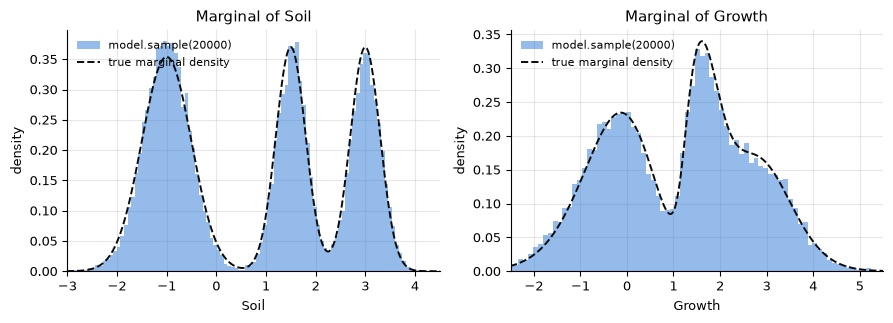

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, node, dens in ((axes[0], "Soil", SOIL_DENSITY), (axes[1], "Growth", GROWTH_DENSITY)):
    ax.hist(to_numpy(draws[node]).ravel(), bins=100, density=True, color=BLUE, alpha=0.5,
            label="model.sample(20000)")
    ax.plot(to_numpy(GRID), to_numpy(dens), color=INK, lw=1.4, ls="--", label="true marginal density")
    ax.set(xlabel=node, ylabel="density", title=f"Marginal of {node}")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_xlim(-3, 4.5)
axes[1].set_xlim(-2.5, 5.5)
fig.tight_layout()
plt.show()

The joint of `Soil` and `Growth` too: the spread of `Growth` is smallest
near `Soil = 1` and grows on both sides.  Left: the model's samples; right:
samples from the true network.

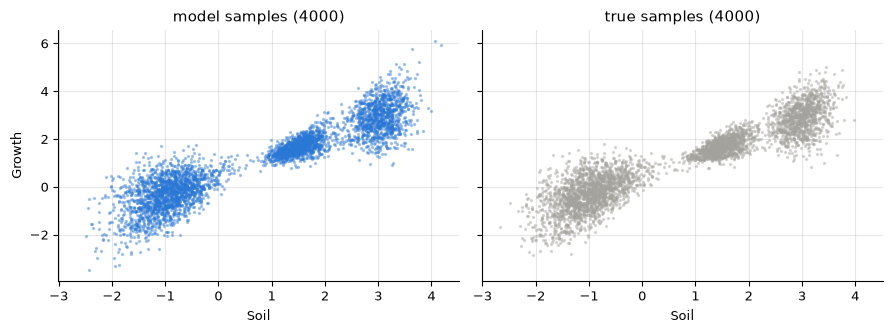

In [5]:
seed_all(2)
truth_draws = sample_truth(4000)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True, sharey=True)
for ax, rows, color, title in ((axes[0], {k: v[:4000] for k, v in draws.items()}, BLUE, "model samples"),
                               (axes[1], truth_draws, GREY, "true samples")):
    ax.scatter(to_numpy(rows["Soil"]), to_numpy(rows["Growth"]), s=2, alpha=0.35, color=color)
    ax.set(xlabel="Soil", title=f"{title} (4000)")
axes[0].set_ylabel("Growth")
fig.tight_layout()
plt.show()

`return_log_prob=True` also returns the joint log-density of every sample under
the model.  It is the same number `log_prob` gives for those rows.

In [6]:
seed_all(3)
with torch.no_grad():
    rows, lp = model.sample(5, return_log_prob=True)
    again = model.log_prob(rows)
print("log-density from sample():", [round(v, 4) for v in to_numpy(lp).tolist()])
print("log_prob() of the same rows:", [round(v, 4) for v in to_numpy(again).tolist()])

log-density from sample(): [-2.7752, -8.7067, -1.414, -2.0694, -3.236]
log_prob() of the same rows: [-2.7752, -8.7067, -1.414, -2.0694, -3.236]


## 2. Evidence and importance weights

`sample(n, evidence={...})` *clamps* the evidence nodes: they take the given
value in every row, and their ancestors are drawn from the prior.  Clamped
samples are therefore **not** posterior samples.  With
`return_log_weight=True` each row also gets `log p(evidence | parents)`;
weighting the rows by `exp(log_weight)` turns them into a posterior estimate
(likelihood weighting).  The effective sample size
`ESS = (sum w)^2 / sum w^2` says how many unweighted samples the weighted ones
are worth.

Below: `P(Rain = 1 | Soil = s)` for 46 observed values of `s`, from 4000
clamped samples each.

In [7]:
def exact_rain_given_soil(s: float) -> float:
    post = []
    for rain in (0, 1):
        post.append(sum(float(JOINT[rain, spr, wet]) * float(soil_pdf(torch.tensor(s), wet))
                        for spr, wet in itertools.product((0, 1), repeat=2)))
    return post[1] / sum(post)


soil_values = np.linspace(-2.5, 4.25, 46)
naive, weighted, ess, exact_p = [], [], [], []
seed_all(4)
for s in soil_values:
    with torch.no_grad():
        rows, log_w = model.sample(4000, evidence={"Soil": float(s)}, return_log_weight=True)
    w = torch.softmax(log_w.cpu(), 0)
    rain = rows["Rain"].reshape(-1).float().cpu()
    naive.append(float(rain.mean()))
    weighted.append(float((w * rain).sum()))
    ess.append(float(1.0 / (w ** 2).sum()) / 4000)
    exact_p.append(exact_rain_given_soil(float(s)))
naive, weighted, ess, exact_p = map(np.array, (naive, weighted, ess, exact_p))
print(f"mean |error| of P(Rain=1 | Soil=s): unweighted {np.abs(naive - exact_p).mean():.3f}, "
      f"weighted {np.abs(weighted - exact_p).mean():.3f}")
for s0 in (-1.0, 0.5, 2.25):
    i = int(np.abs(soil_values - s0).argmin())
    print(f"  Soil = {soil_values[i]:.2f}: unweighted {naive[i]:.3f}, weighted {weighted[i]:.3f}, "
          f"exact {exact_p[i]:.3f}, ESS {ess[i]:.3f} of the samples")

mean |error| of P(Rain=1 | Soil=s): unweighted 0.181, weighted 0.007
  Soil = -1.00: unweighted 0.310, weighted 0.096, exact 0.093, ESS 0.454 of the samples
  Soil = 0.50: unweighted 0.301, weighted 0.198, exact 0.192, ESS 0.787 of the samples
  Soil = 2.30: unweighted 0.311, weighted 0.486, exact 0.465, ESS 0.555 of the samples


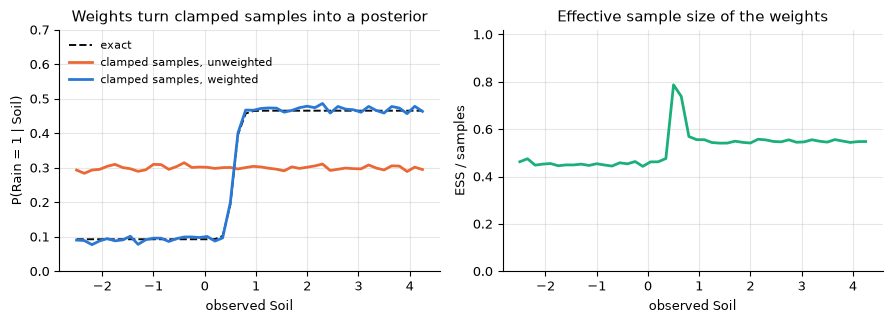

In [8]:
fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(9, 3.3))
ax_p.plot(soil_values, exact_p, color=INK, lw=1.4, ls="--", label="exact")
ax_p.plot(soil_values, naive, color=ORANGE, lw=2, label="clamped samples, unweighted")
ax_p.plot(soil_values, weighted, color=BLUE, lw=2, label="clamped samples, weighted")
ax_p.set(xlabel="observed Soil", ylabel="P(Rain = 1 | Soil)", ylim=(0, 0.7),
         title="Weights turn clamped samples into a posterior")
ax_p.legend(frameon=False, fontsize=8, loc="upper left")
ax_e.plot(soil_values, ess, color=AQUA, lw=2)
ax_e.set(xlabel="observed Soil", ylabel="ESS / samples", ylim=(0, 1.02),
         title="Effective sample size of the weights")
fig.tight_layout()
plt.show()

Left: the unweighted clamped samples ignore the evidence: their rain share
stays at the prior, about 0.30, for every soil value (mean error 0.181).  The
weighted estimate follows the exact posterior (mean error 0.007).

Right: here the evidence weight depends only on `WetGrass`.  Far from the
crossing point, one of the two `WetGrass` states explains the soil value and
the other gets almost no weight, so the ESS is about the prior probability of
that state: about 0.45 for dry soil (`P(WetGrass = 0)` = 0.444) and 0.55 for
wet soil.  Near `Soil = 0.5` both states explain the value about equally, so
the weights are more even and the ESS reaches 0.79.

## 3. Interventional samples

`sample(n, do={...})` draws from the network with the intervened node set to a
value and its incoming edges cut.  Its ancestors keep their prior, unlike
under evidence.

In [9]:
seed_all(5)
with torch.no_grad():
    under_do = {wet: model.sample(20_000, do={"WetGrass": wet}) for wet in (0, 1)}
    rows, log_w = model.sample(20_000, evidence={"WetGrass": 1}, return_log_weight=True)
rain_do = float(under_do[1]["Rain"].float().mean())
w = torch.softmax(log_w.cpu(), 0)
rain_seen = float((w * rows["Rain"].reshape(-1).float().cpu()).sum())
truth_seen = float(JOINT[1, :, 1].sum() / JOINT[:, :, 1].sum())
print(f"P(Rain=1) under do(WetGrass=1): samples {rain_do:.3f}, truth 0.300 (wetting the grass "
      "does not make it rain)")
print(f"P(Rain=1 | WetGrass=1) (weighted): {rain_seen:.3f}, truth {truth_seen:.3f}")

seed_all(6)
with torch.no_grad():
    g = model.sample(20_000, do={"Soil": 3.0})["Growth"]
print(f"Growth under do(Soil=3.0): mean {float(g.mean()):.3f} (truth {0.8 * 3 + 0.5:.3f}), "
      f"sd {float(g.std()):.3f} (truth {0.15 + 0.25 * 2:.3f})")

P(Rain=1) under do(WetGrass=1): samples 0.302, truth 0.300 (wetting the grass does not make it rain)
P(Rain=1 | WetGrass=1) (weighted): 0.466, truth 0.465
Growth under do(Soil=3.0): mean 2.904 (truth 2.900), sd 0.663 (truth 0.650)


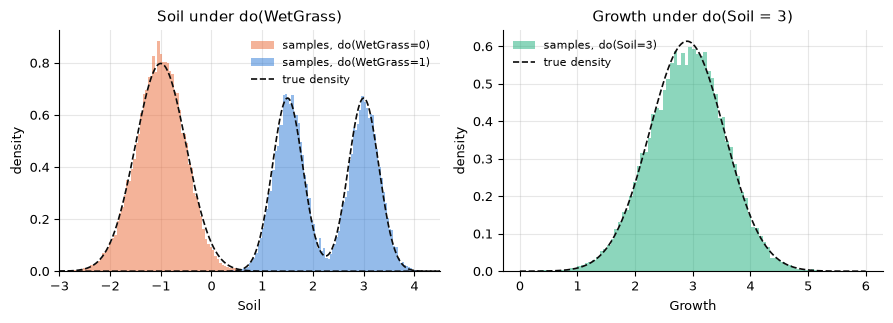

In [10]:
fig, (ax_s, ax_g) = plt.subplots(1, 2, figsize=(9, 3.3))
for wet, color in ((0, ORANGE), (1, BLUE)):
    ax_s.hist(to_numpy(under_do[wet]["Soil"]).ravel(), bins=90, density=True, color=color, alpha=0.5,
              label=f"samples, do(WetGrass={wet})")
    ax_s.plot(to_numpy(GRID), to_numpy(soil_pdf(GRID, wet)), color=INK, lw=1.2, ls="--",
              label="true density" if wet else None)
ax_s.set(xlim=(-3, 4.5), xlabel="Soil", ylabel="density", title="Soil under do(WetGrass)")
ax_s.legend(frameon=False, fontsize=8, loc="upper right")
gg = torch.linspace(0, 6, 400)
ax_g.hist(to_numpy(g).ravel(), bins=80, density=True, color=AQUA, alpha=0.5, label="samples, do(Soil=3)")
ax_g.plot(to_numpy(gg), to_numpy(growth_pdf(gg, torch.tensor(3.0))), color=INK, lw=1.2, ls="--",
          label="true density")
ax_g.set(xlabel="Growth", ylabel="density", title="Growth under do(Soil = 3)")
ax_g.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Left: under `do(WetGrass = w)` the soil follows `p(Soil | WetGrass = w)`: one
mode when dry, two when wet.  Under the intervention the rain share stays at
the prior (0.302 in the samples, truth 0.300), while *observing* wet grass
raises it to 0.466 (truth 0.465).  Right: `do(Soil = 3)` on a continuous node
gives `Growth` with mean 2.904 and sd 0.663 (truth 2.900 and 0.650).